In [46]:
import pandas as pd
import numpy as np
import geopandas as gpd
import shapely
import shapely.geometry
import matplotlib.pyplot as plt
import matplotlib as mpl

This cell does the dirty work: reading in bay tracts, stores (found with google maps API), filtering out unwanted store types and fixing several incorrect classifications. The results are plotted over a map of SF and the East Bay.

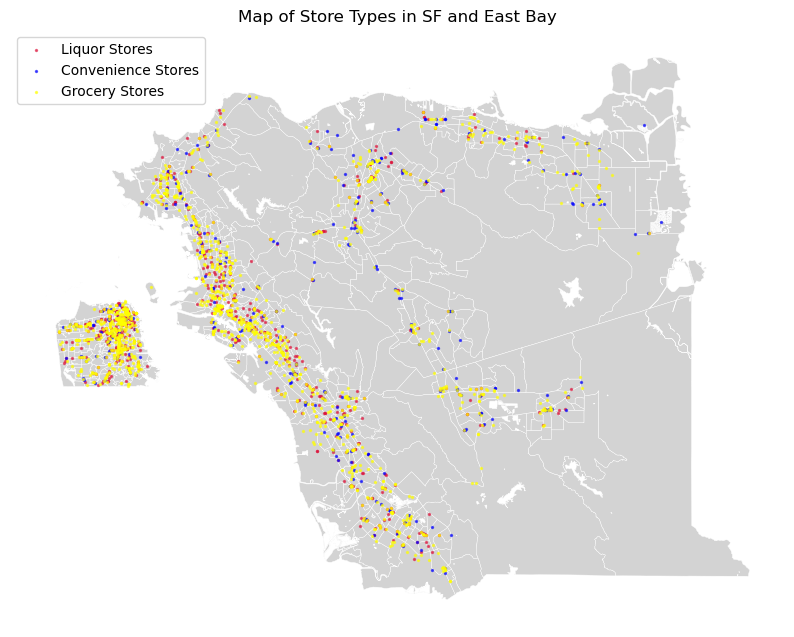

In [55]:
bay = pd.read_csv('Bay-Area-Food-Access/data/bay_tracts', dtype={'geoid': str})
bay_4326 = gpd.GeoDataFrame(bay, geometry=gpd.GeoSeries.from_wkt(bay['geometry']),crs="EPSG:4326")

stores = pd.read_csv('Bay-Area-Food-Access/data/bay_food_places.csv', dtype={'place_id': str, 'name': str, 'found_by': str,})
stores_4326 = gpd.GeoDataFrame(stores, geometry=gpd.GeoSeries.from_wkt(stores['geometry']),crs="EPSG:4326")

grocer_and_convinience = stores_4326[stores_4326['primary_type'].isin(['asian_grocery_store', 'grocery_store', 'convenience_store',
       'market', 'gas_station', 'deli', 'liquor_store', 'farmers_market',
       'drugstore', 'supermarket', 'health_food_store', 'food_store',
       'store', 'wholesaler', 'supplier', 'butcher_shop',
       'hypermarket', 'food'])]

grocer_and_convinience = grocer_and_convinience[grocer_and_convinience['business_status'] == 'OPERATIONAL']
grocer_and_convinience = grocer_and_convinience[~grocer_and_convinience['name'].str.lower().str.contains('smoke|vape|vitamin|cigar')]
grocer_and_convinience = grocer_and_convinience[~grocer_and_convinience['name'].isin(['Natural Haven Co', 'Afikomen Judaica', 'Summer Solace Tallow', 'Llewellyn Marine Supply, Inc', 'The Caviar Co.', "Mooney's", 'Twisted Thistle Apothecary', "Dave's Gourmet"])]
grocer_and_convinience.loc[grocer_and_convinience['name'] == "Sam's Club", 'primary_type'] = 'grocery_store'
grocer_and_convinience.loc[grocer_and_convinience['name'] == "Roxy Trading Inc", 'primary_type'] = 'grocery_store'

liquor_stores = pd.concat([
    grocer_and_convinience[grocer_and_convinience['primary_type'].isin(['liquor_store'])],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'deli') & (grocer_and_convinience['primary_search_type'] == 'liquor_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'market') & (grocer_and_convinience['primary_search_type'] == 'liquor_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'store') & (grocer_and_convinience['primary_search_type'] == 'liquor_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'wholesaler') & (grocer_and_convinience['primary_search_type'] == 'liquor_store')]],
    ignore_index = True
)
convinience_stores = pd.concat([
    grocer_and_convinience[grocer_and_convinience['primary_type'].isin(['convinience_store','gas_station', 'drugstore'])],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'deli') & (grocer_and_convinience['primary_search_type'] == 'convinience_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'market') & (grocer_and_convinience['primary_search_type'] == 'convinience_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'store') & (grocer_and_convinience['primary_search_type'] == 'convinience_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'wholesaler') & (grocer_and_convinience['primary_search_type'] == 'convinience_store')]],
    ignore_index = True
)
grocery_stores = pd.concat([
    grocer_and_convinience[grocer_and_convinience['primary_type'].isin(['asian_grocery_store', 'grocery_store', 'farmers_market', 'supermarket', 'health_food_store', 'food_store', 'butcher_shop', 'hypermarket', 'food',])],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'deli') & (grocer_and_convinience['primary_search_type'] == 'grocery_store')],
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'market') & (grocer_and_convinience['primary_search_type'] == 'grocery_store')], 
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'store') & (grocer_and_convinience['primary_search_type'] == 'grocery_store')],  
    grocer_and_convinience[(grocer_and_convinience['primary_type'] == 'wholesaler') & (grocer_and_convinience['primary_search_type'] == 'grocery_store')]],
    ignore_index = True
)

ax = bay_4326.plot(color="lightgrey", edgecolor="white", linewidth=0.3, figsize=(10, 10))
liquor_stores.plot(ax=ax, markersize=2, color="crimson", alpha=0.6, label="Liquor Stores")
convinience_stores.plot(ax=ax, markersize=2, color="blue", alpha=0.6, label="Convenience Stores")
grocery_stores.plot(ax=ax, markersize=2, color="yellow", alpha=0.6, label="Grocery Stores")
ax.set_title('Map of Store Types in SF and East Bay')
ax.set_axis_off()
ax.legend(loc="upper left", frameon=True);

ax.figure.savefig("Bay-Area-Food-Access/outputs/store_types_map.png", dpi=300, bbox_inches="tight")


To find what food accessibility metrics differentiate neighborhoods the most across the Bay, we will first discretize census tracts into points 500 meters apart on a grid, a method similar to one previously used to sample every census tract at least once. Eventually, for each point, we will define ‘walking distance’ as a walk that takes 15 minutes or less according to Google Maps, ‘biking distance’ as a trip taking 30 minutes or less by bicycle, and ‘transit distance’ as a trip taking 30 minutes or less by transit according to Google Maps. However, for this first pass, we will use using the buffer method: create a radius around each point and sample how many stores are in walking and driving distance. This is an approximation of the results we expect to find when using actual travel time.

The grid is plotted over the bay area for reference of the sampling density.

,geometry,geoid,countyfp,tract,stores_walk_all,stores_drive_all,stores_walk_liquor,stores_drive_liquor,stores_walk_convenience,stores_drive_convenience,stores_walk_grocery,stores_drive_grocery
505,POINT (542858.386 4180801.584),06075047904,75,47904,3,314,1,92,0,26,2,146
506,POINT (542858.386 4181301.584),06075047904,75,47904,3,310,1,88,0,26,2,149
507,POINT (542858.386 4181801.584),06075047904,75,47904,0,309,0,88,0,25,0,147
642,POINT (543358.386 4176801.584),06075035400,75,35400,2,333,2,92,0,25,0,156
643,POINT (543358.386 4177301.584),06075035400,75,35400,1,356,1,98,0,25,0,170


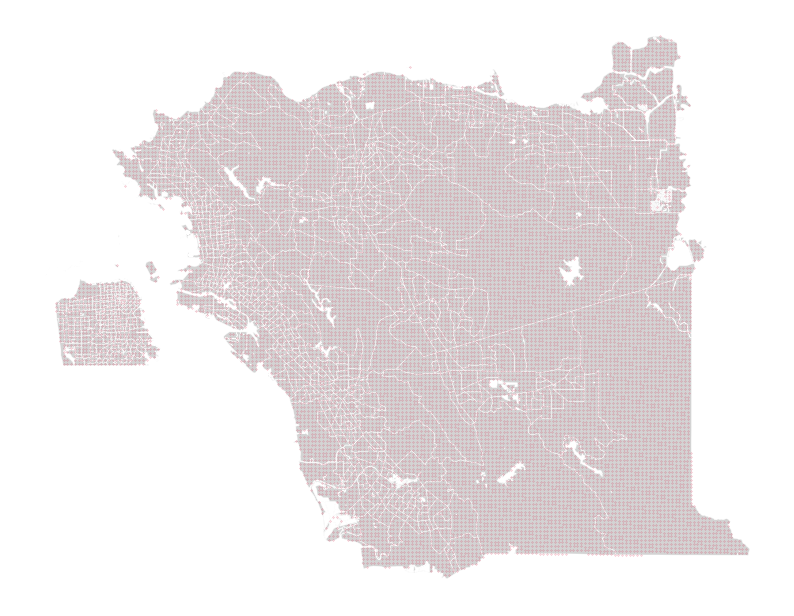

In [45]:
from shapely.geometry import Point
from scipy.spatial import cKDTree

# Set distances
MILE = 1609.344 #meters
WALK  = 0.5 * MILE  # walking distance
DRIVE = 5 * MILE   # driving distance
spacing = 500 # half a kilometer, 0.3 miles

bay_meters = bay_4326.to_crs(epsg=26910) # move to meters to make grid points

# make the grid
minx, miny, maxx, maxy = bay_meters.total_bounds
x_coords = np.arange(minx, maxx, spacing)
y_coords = np.arange(miny, maxy, spacing)
points = [Point(x, y) for x in x_coords for y in y_coords]

# overlay it with the bay tracts
grid_gpd = gpd.GeoDataFrame({'geometry': points}, crs='EPSG:26910')
grid_gpd = gpd.sjoin(grid_gpd, bay_meters, predicate='within') # spatial join!

def count_within(points, stores, radius):
    """For each point, count the stores inside a circle of `radius` meters around it."""
    stores = stores.to_crs(points.crs)
    tree = cKDTree(np.c_[stores.geometry.x, stores.geometry.y])
    return tree.query_ball_point(np.c_[points.geometry.x, points.geometry.y],
                                 radius, return_length=True)

store_dfs = {
    'all': grocer_and_convinience,
    'liquor': liquor_stores,
    'convenience': convinience_stores,
    'grocery': grocery_stores
}

# do the counting!
for name, df in store_dfs.items():
    grid_gpd[f'stores_walk_{name}'] = count_within(grid_gpd, df, WALK)
    grid_gpd[f'stores_drive_{name}'] = count_within(grid_gpd, df, DRIVE)

# 500 meter spacing, plotted
ax = bay_4326.plot(color="lightgrey", edgecolor="white", linewidth=0.3, figsize=(10, 10))
grid_gpd.to_crs(epsg=4326).plot(ax=ax, markersize=0.05, color="crimson", alpha=0.6)
ax.set_axis_off()

grid_gpd = grid_gpd.drop(columns = ['index_right', 'Unnamed: 0'])
grid_gpd.head()

Next, we'll find the average number of stores in walking and driving distance for each tract by averaging the number of stores found above by grouped geoid. Then we'll plot the results for comparison.

In [38]:
#all stores
avg_all_stores = grid_gpd.groupby('geoid')[['stores_walk_all', 'stores_drive_all']].mean().reset_index()
avg_all_stores['geoid'] = avg_all_stores['geoid'].astype('str')
tracts_avg_all_stores = bay_meters.merge(avg_all_stores, on = 'geoid', how = 'left')

#liquor stores
avg_liquor_stores = grid_gpd.groupby('geoid')[['stores_walk_liquor', 'stores_drive_liquor']].mean().reset_index()
avg_liquor_stores['geoid'] = avg_liquor_stores['geoid'].astype('str')
tracts_avg_liquor_stores = bay_meters.merge(avg_liquor_stores, on = 'geoid', how = 'left')

#convenience stores
avg_convenience_stores = grid_gpd.groupby('geoid')[['stores_walk_convenience', 'stores_drive_convenience']].mean().reset_index()
avg_convenience_stores['geoid'] = avg_convenience_stores['geoid'].astype('str')
tracts_avg_convenience_stores = bay_meters.merge(avg_convenience_stores, on = 'geoid', how = 'left')

#grocery stores
avg_grocery_stores = grid_gpd.groupby('geoid')[['stores_walk_grocery', 'stores_drive_grocery']].mean().reset_index()
avg_grocery_stores['geoid'] = avg_grocery_stores['geoid'].astype('str')
tracts_avg_grocery_stores = bay_meters.merge(avg_grocery_stores, on = 'geoid', how = 'left')

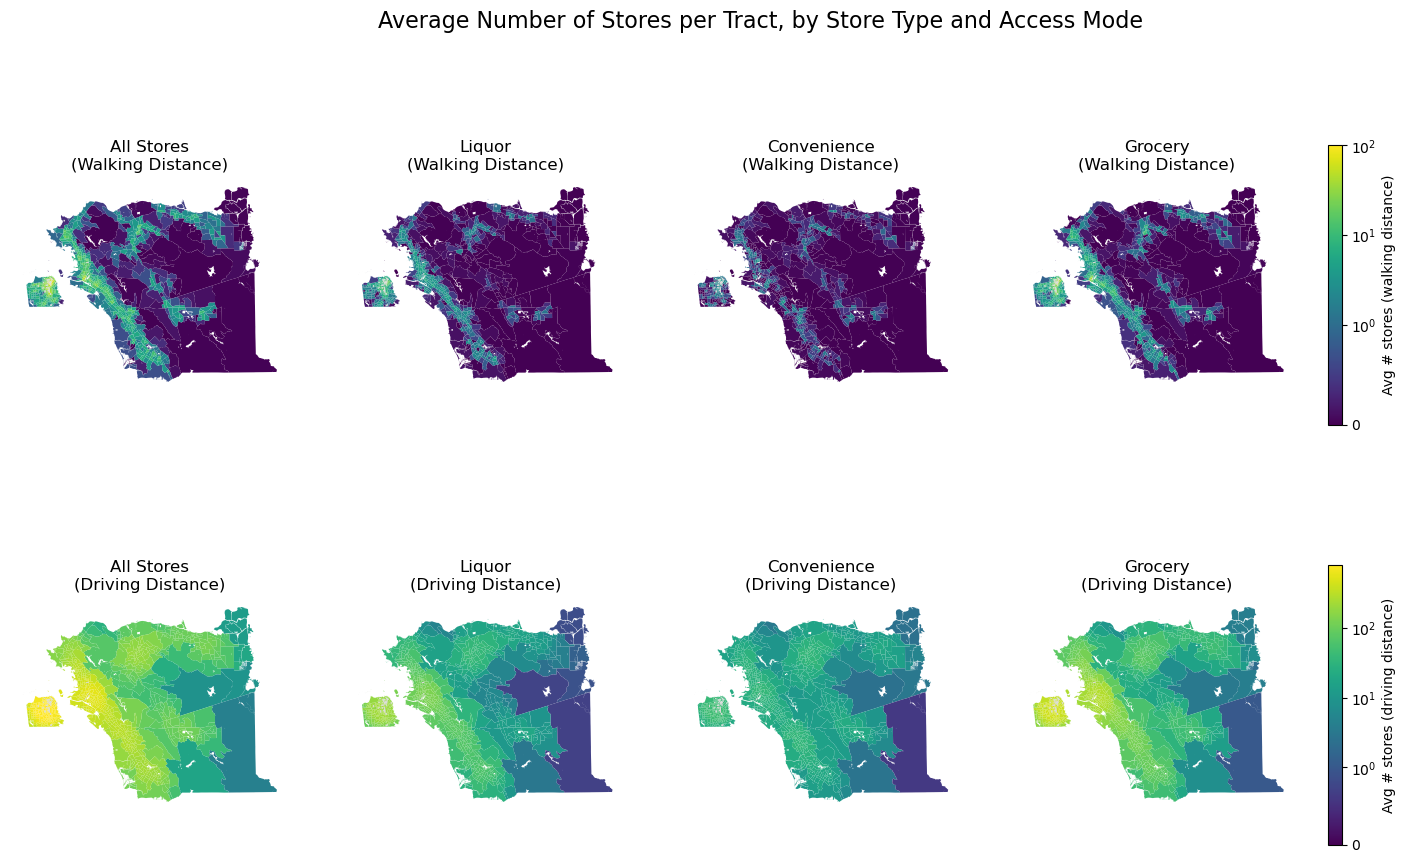

In [56]:
# chlorpleth
from matplotlib.colors import SymLogNorm

# (label, dataframe, column suffix)
layers = [
    ('All Stores',  tracts_avg_all_stores,         'all'),
    ('Liquor',      tracts_avg_liquor_stores,      'liquor'),
    ('Convenience', tracts_avg_convenience_stores, 'convenience'),
    ('Grocery',     tracts_avg_grocery_stores,     'grocery'),
]
modes = {'walk': 'Walking Distance', 'drive': 'Driving Distance'}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for row, (mode, mode_label) in enumerate(modes.items()):
    vmax = max(df[f'stores_{mode}_{suffix}'].max() for _, df, suffix in layers)
    norm = SymLogNorm(linthresh=1, vmin=0, vmax=vmax) # used to make the color scale similar to a log scale, but able to handle 0s

    for col, (label, df, suffix) in enumerate(layers):
        ax = axes[row, col]
        df.plot(ax=ax, column=f'stores_{mode}_{suffix}',
                norm=norm, cmap='viridis',
                missing_kwds={'color': 'lightgrey'})
        ax.set_title(f'{label}\n({mode_label})')
        ax.set_axis_off()

    sm = mpl.cm.ScalarMappable(norm=norm, cmap='viridis')
    fig.colorbar(sm, ax=axes[row, :], shrink=0.8, pad=0.02,
                 label=f'Avg # stores ({mode_label.lower()})')

fig.suptitle('Average Number of Stores per Tract, by Store Type and Access Mode', fontsize=16)

fig.savefig("Bay-Area-Food-Access/outputs/store_access_choropleths.png", dpi=300, bbox_inches="tight")
plt.show()